<a href="https://colab.research.google.com/github/me-greeny/spasio-temporal-sae/blob/main/03_olah_data/STSAE_baru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# BAGIAN 1: LOAD DATA, PEMBERSIHAN, LOGARITMA, STANDARDISASI
# ============================================================

import pandas as pd
import numpy as np
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler
from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Load data dari Google Drive
data_path = "/content/drive/MyDrive/data_skripsi/data_panel_sae_2018_2025.csv"
df = pd.read_csv(data_path)
print("Ukuran data awal:", df.shape)
display(df.head())

# 3. Urutkan data panel
df = df.sort_values(["kode_kecamatan_bps", "tahun"]).reset_index(drop=True)
print(df[["kode_kecamatan_bps", "tahun", "pengeluaran_mean"]].head())

# 4. Definisi variabel penelitian
target = "pengeluaran_mean"
sampling_var = "VAR...8"
area_col = "kode_kecamatan_bps"
time_col = "tahun"

# Variabel penyerta awal
aux_vars_original = ["listrik", "pendidikan", "ekonomi", "CO", "LST", "NDBI", "NDVI", "NTL"]

# Cek ketersediaan variabel
missing_vars = [x for x in [target] + aux_vars_original if x not in df.columns]
if len(missing_vars) > 0:
    print("Variabel tidak ditemukan:", missing_vars)
else:
    print("Semua variabel tersedia")

# 5. Pemeriksaan distribusi awal
print("\n=== SKEWNESS AWAL ===")
for var in ["pengeluaran_mean", "NTL", "ekonomi"]:
    skew_value = stats.skew(df[var].dropna())
    print(f"{var}: {round(skew_value, 4)}")

# 6. Transformasi logaritma
df["ln_pengeluaran"] = np.log(df["pengeluaran_mean"])

# NTL
if abs(stats.skew(df["NTL"].dropna())) > 0.5:
    min_ntl = df["NTL"].min()
    shift_ntl = abs(min_ntl) + 1 if min_ntl <= 0 else 0
    df["NTL_ln"] = np.log(df["NTL"] + shift_ntl) if min_ntl <= 0 else np.log(df["NTL"])
else:
    df["NTL_ln"] = df["NTL"]

# Ekonomi
if abs(stats.skew(df["ekonomi"].dropna())) > 0.5:
    min_eko = df["ekonomi"].min()
    shift_eko = abs(min_eko) + 1 if min_eko <= 0 else 0
    df["ekonomi_ln"] = np.log(df["ekonomi"] + shift_eko) if min_eko <= 0 else np.log(df["ekonomi"])
else:
    df["ekonomi_ln"] = df["ekonomi"]

# 7. Pemeriksaan hasil transformasi
print("\n=== SKEWNESS SETELAH TRANSFORMASI ===")
for var in ["ln_pengeluaran", "NTL_ln", "ekonomi_ln"]:
    print(f"{var}: {round(stats.skew(df[var].dropna()), 4)}")

# 8. Standardisasi variabel penyerta
vars_standardisasi = ["NTL_ln", "LST", "NDVI", "NDBI", "CO", "pendidikan", "ekonomi_ln", "listrik"]
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[[x + "_z" for x in vars_standardisasi]] = scaler.fit_transform(df[vars_standardisasi])

# 9. Nama variabel final untuk model
aux_vars_model = [x + "_z" for x in vars_standardisasi]
print("\nVariabel model akhir:", aux_vars_model)

# 10. Dataset final yang digunakan
df_run = df_scaled.sort_values(["kode_kecamatan_bps", "tahun"]).reset_index(drop=True)
print("\nUkuran data final:", df_run.shape)
display(df_run[["kode_kecamatan_bps", "tahun", "pengeluaran_mean", "ln_pengeluaran"]].head())

Mounted at /content/drive
Ukuran data awal: (5288, 39)


,Unnamed: 0,X,kode_kecamatan_bps,tahun,jumlah_rt,Jumlah.Sampel.Rumah.Tangga.Tertimbang,jumlah_individu,Jumlah.Sampel.Individu.Tertimbang,pengeluaran_mean,SE...7,...,kode_clean,CO,LST,NDBI,NDVI,NTL,kecamatan_clean,nama_kecamatan_bps,nama_kecamatan_kemendagri,kode_kecamatan_kemendagri
0,1,1,3501010,2018,50,9876.842209,148,29929.22244,6.614733e+05,63515.45310,...,350101.0,0.027352,30.600439,-0.117859,0.644609,0.409157,DONOROJO,Donorojo,Donorojo,35.01.01
1,2,2,3501020,2018,40,10206.132030,140,35589.90827,1.228464e+06,27201.52200,...,350102.0,0.027383,30.242884,-0.175430,0.637773,0.416408,PUNUNG,Punung,Punung,35.01.03
2,3,3,3501030,2018,40,9279.049225,126,30242.08989,7.072243e+05,130190.16830,...,350103.0,0.027906,29.759502,-0.089270,0.669455,0.369919,PRINGKUKU,Pringkuku,Pringkuku,35.01.02
3,4,4,3501040,2018,70,27892.622030,227,81256.34904,1.203583e+06,181850.68750,...,350104.0,0.028344,31.004505,-0.084315,0.623598,1.424274,PACITAN,Pacitan,Pacitan,35.01.04
4,5,5,3501050,2018,60,12516.486080,213,44668.26711,5.529574e+05,85742.90815,...,350105.0,0.028348,27.917481,-0.145224,0.683647,0.402337,KEBONAGUNG,Kebonagung,Kebonagung,35.01.05


   kode_kecamatan_bps  tahun  pengeluaran_mean
0             3501010   2018       661473.3105
1             3501010   2019       727571.1022
2             3501010   2020       670954.6408
3             3501010   2021       749145.0514
4             3501010   2022       648363.9275
Semua variabel tersedia

=== SKEWNESS AWAL ===
pengeluaran_mean : 3.3
NTL : 3.8664
ekonomi : 3.104

=== SKEWNESS SETELAH TRANSFORMASI ===
ln_pengeluaran : 0.5058
NTL_ln : 0.8769
ekonomi_ln : 0.0386

Variabel model akhir:
['NTL_ln_z', 'LST_z', 'NDVI_z', 'NDBI_z', 'CO_z', 'pendidikan_z', 'ekonomi_ln_z', 'listrik_z']

Ukuran data final: (5288, 50)


,kode_kecamatan_bps,tahun,pengeluaran_mean,ln_pengeluaran
0,3501010,2018,661473.3105,13.402225
1,3501010,2019,727571.1022,13.497467
2,3501010,2020,670954.6408,13.416457
3,3501010,2021,749145.0514,13.526688
4,3501010,2022,648363.9275,13.382207


In [ ]:
# ============================================================
# BAGIAN 2: PEMBENTUKAN KOMPONEN SPASIAL
# ============================================================

import geopandas as gpd
import libpysal
from libpysal.weights import Queen
import numpy as np
import pandas as pd

# 1. Load shapefile kecamatan Jawa Timur
shp_path = "/content/drive/MyDrive/data_skripsi/kecamatan_jatim.shp"
gdf = gpd.read_file(shp_path)
print("Jumlah kecamatan pada peta:", len(gdf))
display(gdf.head())

# 2. Pemeriksaan struktur shapefile
print(gdf.columns)

# 3. Penyamaan format kode kecamatan
gdf["kode_kec"] = gdf["kode_kec"].astype(str).str.strip()
df_run["kode_kecamatan_kemendagri"] = df_run["kode_kecamatan_kemendagri"].astype(str).str.strip()
print(gdf["kode_kec"].head())
print(df_run["kode_kecamatan_kemendagri"].head())

# 4. Merge data panel dengan geometri
gdf_panel = gdf.merge(
    df_run[["kode_kecamatan_kemendagri"]].drop_duplicates(),
    left_on="kode_kec",
    right_on="kode_kecamatan_kemendagri",
    how="inner"
)
print("Jumlah kecamatan setelah merge:", len(gdf_panel))

# 5. Pastikan sistem koordinat
gdf_panel = gdf_panel.to_crs("EPSG:4326") if gdf_panel.crs is not None else gdf_panel.set_crs("EPSG:4326")

# 6. Membuat Queen Contiguity
W = Queen.from_dataframe(gdf_panel, use_index=False)
W.transform = "R"
print("Jumlah wilayah:", W.n)
for i in range(5):
    print(f"Tetangga {i}: {W.neighbors[i]}")

# 7. Pemeriksaan wilayah tanpa tetangga
no_neighbor = [i for i, v in W.neighbors.items() if len(v) == 0]
print("Wilayah tanpa tetangga:", no_neighbor)

# 8. Fungsi spatial smoothing dan efek spasial/temporal
def spatial_smooth(values, W):
    result = np.zeros(len(values))
    for i in range(len(values)):
        neighbors = W.neighbors[i]
        weights = W.weights[i]
        if len(neighbors) == 0:
            result[i] = 0
        else:
            result[i] = sum(w * values[j] for w, j in zip(weights, neighbors))
    return result

def create_spatial_effect(df_model, residual, W):
    spatial_effect = np.zeros(len(df_model))
    years = df_model["tahun"].unique()
    for year in years:
        idx = df_model["tahun"] == year
        spatial_effect[idx] = spatial_smooth(residual[idx].values, W)
    return spatial_effect

def create_temporal_effect(df_model, residual):
    temp_df = df_model.copy()
    temp_df["residual"] = residual
    temporal_effect = temp_df.groupby("kode_kecamatan_bps")["residual"].shift(1)
    area_mean = temp_df.groupby("kode_kecamatan_bps")["residual"].transform("mean")
    temporal_effect = temporal_effect.fillna(area_mean).fillna(0)
    return temporal_effect.values

print("Komponen spasial siap digunakan")
display(gdf_panel.head())

Jumlah kecamatan pada peta: 666


,kode_kec,kode_kk,kode_pro,kecamata,kab_kota,provinsi,fid,nama,label,geometry
0,35.27.13,35.27,35,Pangarengan,Sampang,Jawa Timur,35.27.13,Kecamatan Pangarengan,"Kecamatan Pangarengan, Kabupaten Sampang, Prov...","POLYGON ((113.20778 -7.20488, 113.20778 -7.204..."
1,35.27.14,35.27,35,Karangpenang,Sampang,Jawa Timur,35.27.14,Kecamatan Karangpenang,"Kecamatan Karangpenang, Kabupaten Sampang, Pro...","POLYGON ((113.39267 -7.05756, 113.3928 -7.0583..."
2,35.27.11,35.27,35,Sokobanah,Sampang,Jawa Timur,35.27.11,Kecamatan Sokobanah,"Kecamatan Sokobanah, Kabupaten Sampang, Provin...","POLYGON ((113.37603 -6.9748, 113.37596 -6.9748..."
3,35.27.12,35.27,35,Ketapang,Sampang,Jawa Timur,35.27.12,Kecamatan Ketapang,"Kecamatan Ketapang, Kabupaten Sampang, Provins...","POLYGON ((113.30066 -6.96427, 113.30036 -6.965..."
4,35.27.10,35.27,35,Robatal,Sampang,Jawa Timur,35.27.10,Kecamatan Robatal,"Kecamatan Robatal, Kabupaten Sampang, Provinsi...","POLYGON ((113.3304 -7.03839, 113.33052 -7.0385..."


Index(['kode_kec', 'kode_kk', 'kode_pro', 'kecamata', 'kab_kota', 'provinsi',
       'fid', 'nama', 'label', 'geometry'],
      dtype='object')
0    35.27.13
1    35.27.14
2    35.27.11
3    35.27.12
4    35.27.10
Name: kode_kec, dtype: object
0    35.01.01
1    35.01.01
2    35.01.01
3    35.01.01
4    35.01.01
Name: kode_kecamatan_kemendagri, dtype: object
Jumlah kecamatan setelah merge: 661


/tmp/ipykernel_722/3122929951.py:158: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  W = Queen.from_dataframe(


('WARNING: ', 524, ' is an island (no neighbors)')
('WARNING: ', 530, ' is an island (no neighbors)')
('WARNING: ', 550, ' is an island (no neighbors)')
('WARNING: ', 551, ' is an island (no neighbors)')
('WARNING: ', 552, ' is an island (no neighbors)')
Jumlah wilayah: 661
0 [16, 10, 11, 15]
1 [2, 4, 71, 9, 75]
2 [1, 82, 3, 4, 75]
3 [2, 4, 13]
4 [1, 2, 3, 9, 13, 14]
Wilayah tanpa tetangga: [524, 530, 550, 551, 552]
Komponen spasial siap digunakan


/usr/local/lib/python3.13/dist-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 9 disconnected components.
 There are 5 islands with ids: 524, 530, 550, 551, 552.
  W.__init__(self, neighbors, ids=ids, **kw)


,kode_kec,kode_kk,kode_pro,kecamata,kab_kota,provinsi,fid,nama,label,geometry,kode_kecamatan_kemendagri
0,35.27.13,35.27,35,Pangarengan,Sampang,Jawa Timur,35.27.13,Kecamatan Pangarengan,"Kecamatan Pangarengan, Kabupaten Sampang, Prov...","POLYGON ((113.20778 -7.20488, 113.20778 -7.204...",35.27.13
1,35.27.14,35.27,35,Karangpenang,Sampang,Jawa Timur,35.27.14,Kecamatan Karangpenang,"Kecamatan Karangpenang, Kabupaten Sampang, Pro...","POLYGON ((113.39267 -7.05756, 113.3928 -7.0583...",35.27.14
2,35.27.11,35.27,35,Sokobanah,Sampang,Jawa Timur,35.27.11,Kecamatan Sokobanah,"Kecamatan Sokobanah, Kabupaten Sampang, Provin...","POLYGON ((113.37603 -6.9748, 113.37596 -6.9748...",35.27.11
3,35.27.12,35.27,35,Ketapang,Sampang,Jawa Timur,35.27.12,Kecamatan Ketapang,"Kecamatan Ketapang, Kabupaten Sampang, Provins...","POLYGON ((113.30066 -6.96427, 113.30036 -6.965...",35.27.12
4,35.27.10,35.27,35,Robatal,Sampang,Jawa Timur,35.27.10,Kecamatan Robatal,"Kecamatan Robatal, Kabupaten Sampang, Provinsi...","POLYGON ((113.3304 -7.03839, 113.33052 -7.0385...",35.27.10


=== Korelasi Variabel Penyerta ===


,Variabel,Korelasi
0,NTL_ln_z,0.532388
2,NDVI_z,-0.431091
6,ekonomi_ln_z,0.311883
7,listrik_z,0.297547
1,LST_z,0.181643
3,NDBI_z,0.159059
4,CO_z,0.062077
5,pendidikan_z,0.012568


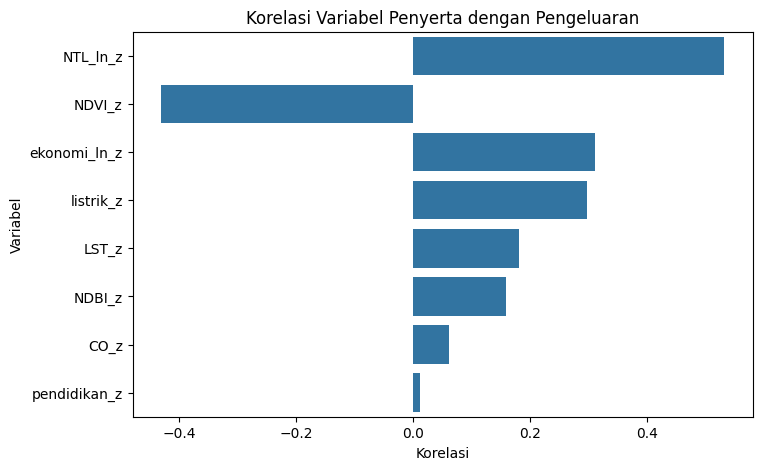

=== Nilai VIF ===


,Variabel,VIF
2,LST_z,4.710103
3,NDVI_z,3.080448
1,NTL_ln_z,2.916635
8,listrik_z,2.731940
5,CO_z,2.355529
7,ekonomi_ln_z,2.330499
4,NDBI_z,2.234962
6,pendidikan_z,1.760523


=== Variabel Terpilih LASSO ===
['NTL_ln_z', 'LST_z', 'NDVI_z', 'NDBI_z', 'CO_z', 'pendidikan_z', 'ekonomi_ln_z', 'listrik_z']


,Variabel,Koefisien
0,NTL_ln_z,0.156909
1,LST_z,-0.092195
2,NDVI_z,-0.119093
3,NDBI_z,-0.007350
4,CO_z,-0.024643
5,pendidikan_z,-0.064304
6,ekonomi_ln_z,0.063755
7,listrik_z,0.019831


=== Variabel Terpilih Stepwise AIC ===
['NTL_ln_z', 'LST_z', 'NDVI_z', 'CO_z', 'pendidikan_z', 'ekonomi_ln_z', 'listrik_z']


,Metode,Variabel Terpilih
0,LASSO,"NTL_ln_z, LST_z, NDVI_z, NDBI_z, CO_z, pendidi..."
1,Backward Stepwise AIC,"NTL_ln_z, LST_z, NDVI_z, CO_z, pendidikan_z, e..."


,Model,Jumlah Variabel,Variabel
0,M221,6,"NTL_ln_z, LST_z, NDBI_z, CO_z, pendidikan_z, e..."
1,M165,5,"NTL_ln_z, LST_z, NDBI_z, CO_z, pendidikan_z"
2,M87,4,"NTL_ln_z, LST_z, NDVI_z, pendidikan_z"
3,M4,3,"LST_z, pendidikan_z, ekonomi_ln_z"


In [ ]:
# ============================================================
# BAGIAN 3: SELEKSI VARIABEL PENYERTA DAN MODEL KANDIDAT
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LassoCV
from sklearn.feature_selection import SequentialFeatureSelector
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

candidate_vars = ["NTL_ln_z", "LST_z", "NDVI_z", "NDBI_z", "CO_z", "pendidikan_z", "ekonomi_ln_z", "listrik_z"]
target_var = "ln_pengeluaran"

# 1. Korelasi variabel penyerta dengan pengeluaran
corr_results = []
for var in candidate_vars:
    corr = df_run[[var, target_var]].corr().iloc[0, 1]
    corr_results.append({"Variabel": var, "Korelasi": corr})
df_corr = pd.DataFrame(corr_results).sort_values("Korelasi", key=abs, ascending=False)
print("=== Korelasi Variabel Penyerta ===")
display(df_corr)

# Visualisasi korelasi
plt.figure(figsize=(8, 5))
sns.barplot(data=df_corr, x="Korelasi", y="Variabel")
plt.title("Korelasi Variabel Penyerta dengan Pengeluaran")
plt.show()

# 2. Uji Multikolinearitas VIF
X_vif = sm.add_constant(df_run[candidate_vars].copy())
vif_table = pd.DataFrame()
vif_table["Variabel"] = X_vif.columns
vif_table["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif_table = vif_table[vif_table["Variabel"] != "const"].sort_values("VIF", ascending=False)
print("=== Nilai VIF ===")
display(vif_table)

# 3. Seleksi LASSO
X = df_run[candidate_vars]
y = df_run[target_var]
lasso = LassoCV(cv=10, random_state=123, max_iter=10000).fit(X, y)
lasso_result = pd.DataFrame({"Variabel": candidate_vars, "Koefisien": lasso.coef_})
lasso_selected = lasso_result[lasso_result["Koefisien"] != 0]["Variabel"].tolist()
print("=== Variabel Terpilih LASSO ===", lasso_selected)
display(lasso_result)

# 4. Seleksi Backward Stepwise AIC
def backward_stepwise_aic(X, y):
    variables = list(X.columns)
    while True:
        X_model = sm.add_constant(X[variables])
        model = sm.OLS(y, X_model).fit()
        current_aic = model.aic
        aic_candidates = []
        for var in variables:
            temp_vars = variables.copy()
            temp_vars.remove(var)
            X_temp = sm.add_constant(X[temp_vars])
            temp_model = sm.OLS(y, X_temp).fit()
            aic_candidates.append({"remove": var, "aic": temp_model.aic})
        result = pd.DataFrame(aic_candidates)
        best = result.loc[result["aic"].idxmin()]
        if best["aic"] < current_aic:
            variables.remove(best["remove"])
        else:
            break
    return variables

stepwise_selected = backward_stepwise_aic(df_run[candidate_vars], df_run[target_var])
print("=== Variabel Terpilih Stepwise AIC ===", stepwise_selected)

# 5. Gabungkan hasil seleksi
selection_summary = pd.DataFrame({
    "Metode": ["LASSO", "Backward Stepwise AIC"],
    "Variabel Terpilih": [", ".join(lasso_selected), ", ".join(stepwise_selected)]
})
display(selection_summary)

# 6. Definisi MODEL ST-SAE
selected_models = {
    "M221": ["NTL_ln_z", "LST_z", "NDBI_z", "CO_z", "pendidikan_z", "ekonomi_ln_z"],
    "M165": ["NTL_ln_z", "LST_z", "NDBI_z", "CO_z", "pendidikan_z"],
    "M87": ["NTL_ln_z", "LST_z", "NDVI_z", "pendidikan_z"],
    "M4": ["LST_z", "pendidikan_z", "ekonomi_ln_z"]
}

model_table = [{"Model": k, "Jumlah Variabel": len(v), "Variabel": ", ".join(v)} for k, v in selected_models.items()]
df_model_table = pd.DataFrame(model_table)
display(df_model_table)

In [ ]:
# ============================================================
# BAGIAN 4: PEMODELAN ST-SAE (EBLUP, BOOTSTRAP MSE, RSE)
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

def calculate_spatial_effect(df_model, residual, W):
    spatial_effect = np.zeros(len(df_model))
    for year in df_model["tahun"].unique():
        idx = df_model["tahun"] == year
        residual_year = residual[idx]
        spatial_effect[idx] = spatial_smooth(residual_year.values, W)
    return spatial_effect

def calculate_temporal_effect(df_model, residual):
    temp_df = df_model.copy()
    temp_df["residual"] = residual
    temporal_effect = temp_df.sort_values(["kode_kecamatan_bps", "tahun"]).groupby("kode_kecamatan_bps")["residual"].shift(1)
    area_mean = temp_df.groupby("kode_kecamatan_bps")["residual"].transform("mean")
    temporal_effect = temporal_effect.fillna(area_mean).fillna(0)
    return temporal_effect.values

def bootstrap_mse_sae(eblup, variance_sampling, sigma_model, B=200):
    bootstrap_estimates = []
    for b in range(B):
        model_error = np.random.normal(0, np.sqrt(sigma_model), size=len(eblup))
        sampling_error = np.random.normal(0, np.sqrt(variance_sampling), size=len(eblup))
        simulated = eblup + model_error + sampling_error
        bootstrap_estimates.append(simulated)
    bootstrap_estimates = np.array(bootstrap_estimates)
    mse = ((bootstrap_estimates - eblup.values) ** 2).mean(axis=0)
    return mse

def run_stsae_model(df_model, variables, W, B=200):
    # A. Model dasar WLS
    X_base = sm.add_constant(df_model[variables])
    base_fit = sm.WLS(df_model["ln_pengeluaran"], X_base, weights=1/df_model["VAR...8"]).fit()
    residual = df_model["ln_pengeluaran"] - base_fit.predict(X_base)

    # B. Spatial & Temporal effects
    spatial_effect = calculate_spatial_effect(df_model, residual, W)
    temporal_effect = calculate_temporal_effect(df_model, residual)

    # C. Model ST-SAE
    df_temp = df_model.copy()
    df_temp["spatial_effect"] = spatial_effect
    df_temp["temporal_effect"] = temporal_effect
    st_variables = variables + ["spatial_effect", "temporal_effect"]
    X_st = sm.add_constant(df_temp[st_variables])
    st_fit = sm.WLS(df_temp["ln_pengeluaran"], X_st, weights=1/df_temp["VAR...8"]).fit()

    # D. EBLUP & Back transformation
    pred_log = st_fit.predict(X_st)
    sigma_u = np.var(residual)
    gamma = sigma_u / (sigma_u + df_temp["VAR...8"])
    eblup_log = gamma * df_temp["ln_pengeluaran"] + (1 - gamma) * pred_log
    sigma2 = np.var(st_fit.resid, ddof=1)
    bias_correction = np.exp(0.5 * sigma2)
    eblup_original = np.exp(eblup_log) * bias_correction

    # E. Bootstrap MSE & RSE
    mse = bootstrap_mse_sae(pd.Series(eblup_original), df_temp["VAR...8"], sigma_u, B=B)
    rmse = np.sqrt(mse)
    rse = (rmse / eblup_original) * 100

    return {
        "fit": st_fit,
        "eblup": eblup_original,
        "MSE": mse,
        "RMSE": rmse,
        "RSE": rse,
        "data": df_temp
    }

In [ ]:
# ============================================================
# MENJALANKAN MODEL
# ============================================================

model_results = {}
for model_name, variables in selected_models.items():
    print("Running", model_name)
    model_results[model_name] = run_stsae_model(df_run, variables, W, B=200)
print("Semua model selesai")

Running M221
Running M165
Running M87
Running M4
Semua model selesai


In [ ]:
# ============================================================
# RINGKASAN MODEL
# ============================================================

evaluation = []
for model_name, result in model_results.items():
    fit = result["fit"]
    rse = result["RSE"]
    mse = result["MSE"]
    evaluation.append({
        "Model": model_name,
        "AIC": fit.aic,
        "BIC": fit.bic,
        "Mean_MSE": np.mean(mse),
        "Median_MSE": np.median(mse),
        "Mean_RSE": np.mean(rse),
        "Median_RSE": np.median(rse),
        "RSE < 25%": np.mean(rse < 25) * 100
    })

df_model_eval = pd.DataFrame(evaluation).sort_values("Mean_RSE").reset_index(drop=True)
display(df_model_eval)

,Model,AIC,BIC,Mean_MSE,Median_MSE,Mean_RSE,Median_RSE,RSE < 25%
0,M4,360485.812431,360525.251604,4.348836e+10,9.210994e+09,7.832028,4.876512,95.555976
1,M87,359226.010138,359272.022506,4.367155e+10,9.205593e+09,8.456106,5.986389,95.366868
2,M221,359680.042710,359739.201468,4.337012e+10,9.348687e+09,8.630758,6.059645,95.158850
3,M165,359553.865412,359606.450975,4.505660e+10,9.280250e+09,8.795809,6.150876,95.121029


In [ ]:
# ============================================================
# BAGIAN 5
# VISUALISASI HASIL ST-SAE
# ============================================================


# =========================
# Import library
# =========================

import matplotlib.pyplot as plt

import seaborn as sns

import geopandas as gpd

import pandas as pd

import numpy as np

In [ ]:
# ============================================================
# MEMBUAT DATA FRAME HASIL ESTIMASI
# ============================================================

df_estimation = df_run[["kode_kecamatan_bps", "kode_kecamatan_kemendagri", "tahun", "pengeluaran_mean"]].copy()
df_estimation.rename(columns={"pengeluaran_mean": "Direct_Estimate"}, inplace=True)

for model_name, result in model_results.items():
    df_estimation[f"STSAE_{model_name}"] = result["eblup"]

display(df_estimation.head())

,kode_kecamatan_bps,kode_kecamatan_kemendagri,tahun,Direct_Estimate,STSAE_M221,STSAE_M165,STSAE_M87,STSAE_M4
0,3501010,35.01.01,2018,661473.3105,7.834733e+05,7.713756e+05,7.419815e+05,1.097998e+06
1,3501010,35.01.01,2019,727571.1022,8.246518e+05,8.359024e+05,7.425166e+05,9.960477e+05
2,3501010,35.01.01,2020,670954.6408,9.712536e+05,9.714492e+05,9.859069e+05,1.254513e+06
3,3501010,35.01.01,2021,749145.0514,1.141799e+06,1.124267e+06,1.196836e+06,1.585198e+06
4,3501010,35.01.01,2022,648363.9275,1.258967e+06,1.222934e+06,1.194663e+06,1.578845e+06


In [ ]:
# ============================================================
# MERGE HASIL ESTIMASI DENGAN PETA
# ============================================================

gdf_result = gdf_panel.merge(df_estimation, on="kode_kecamatan_kemendagri", how="inner")
print("Jumlah wilayah peta:", len(gdf_result))
display(gdf_result.head())

Jumlah wilayah peta: 5288


,kode_kec,kode_kk,kode_pro,kecamata,kab_kota,provinsi,fid,nama,label,geometry,kode_kecamatan_kemendagri,kode_kecamatan_bps,tahun,Direct_Estimate,STSAE_M221,STSAE_M165,STSAE_M87,STSAE_M4
0,35.27.13,35.27,35,Pangarengan,Sampang,Jawa Timur,35.27.13,Kecamatan Pangarengan,"Kecamatan Pangarengan, Kabupaten Sampang, Prov...","POLYGON ((113.20778 -7.20488, 113.20778 -7.204...",35.27.13,3527021,2018,844516.9106,749124.576814,712215.853223,8.897424e+05,713052.598982
1,35.27.13,35.27,35,Pangarengan,Sampang,Jawa Timur,35.27.13,Kecamatan Pangarengan,"Kecamatan Pangarengan, Kabupaten Sampang, Prov...","POLYGON ((113.20778 -7.20488, 113.20778 -7.204...",35.27.13,3527021,2019,601528.1768,611288.721624,586310.474522,7.038562e+05,592752.596481
2,35.27.13,35.27,35,Pangarengan,Sampang,Jawa Timur,35.27.13,Kecamatan Pangarengan,"Kecamatan Pangarengan, Kabupaten Sampang, Prov...","POLYGON ((113.20778 -7.20488, 113.20778 -7.204...",35.27.13,3527021,2020,741671.2995,564162.452780,554586.293329,5.768965e+05,492839.059981
3,35.27.13,35.27,35,Pangarengan,Sampang,Jawa Timur,35.27.13,Kecamatan Pangarengan,"Kecamatan Pangarengan, Kabupaten Sampang, Prov...","POLYGON ((113.20778 -7.20488, 113.20778 -7.204...",35.27.13,3527021,2021,787630.2762,716387.951222,707132.777190,9.577097e+05,873171.539375
4,35.27.13,35.27,35,Pangarengan,Sampang,Jawa Timur,35.27.13,Kecamatan Pangarengan,"Kecamatan Pangarengan, Kabupaten Sampang, Prov...","POLYGON ((113.20778 -7.20488, 113.20778 -7.204...",35.27.13,3527021,2022,623929.6318,860580.051165,850728.667867,1.104300e+06,906259.043046


In [ ]:
# ============================================================
# AGREGASI RATA-RATA 2018-2025
# ============================================================

map_average = gdf_result.groupby(
    ["kode_kecamatan_kemendagri", "kecamata", "kab_kota", "geometry"], as_index=False
)[["Direct_Estimate", "STSAE_M221", "STSAE_M165", "STSAE_M87", "STSAE_M4"]].mean()

map_average = gpd.GeoDataFrame(map_average, geometry="geometry", crs=gdf_result.crs)
display(map_average.head())

,kode_kecamatan_kemendagri,kecamata,kab_kota,geometry,Direct_Estimate,STSAE_M221,STSAE_M165,STSAE_M87,STSAE_M4
0,35.01.01,Donorojo,Pacitan,"MULTIPOLYGON (((110.91732 -8.22228, 110.91732 ...",7.066889e+05,9.814980e+05,9.642765e+05,9.265292e+05,1.226428e+06
1,35.01.02,Pringkuku,Pacitan,"MULTIPOLYGON (((110.99356 -8.25564, 110.99352 ...",7.264568e+05,1.008759e+06,1.000697e+06,9.471029e+05,1.279662e+06
2,35.01.03,Punung,Pacitan,"POLYGON ((110.99299 -8.17641, 110.99279 -8.176...",9.409417e+05,1.452317e+06,1.413692e+06,1.376523e+06,1.888530e+06
3,35.01.04,Pacitan,Pacitan,"POLYGON ((111.12723 -8.2265, 111.12717 -8.2264...",1.351963e+06,3.013040e+06,2.876406e+06,2.945040e+06,4.287115e+06
4,35.01.05,Kebonagung,Pacitan,"MULTIPOLYGON (((111.1591 -8.27633, 111.15906 -...",8.191196e+05,1.535625e+06,1.610094e+06,1.652040e+06,2.462780e+06


In [ ]:
# ============================================================
# HANDLING OUTLIER UNTUK VISUALISASI
# ============================================================

max_visual = 8_000_000
map_visual = map_average.copy()
visual_columns = ["Direct_Estimate", "STSAE_M221", "STSAE_M165", "STSAE_M87", "STSAE_M4"]
for col in visual_columns:
    map_visual[col + "_plot"] = map_visual[col].clip(upper=max_visual)

display(map_visual[visual_columns + [x + "_plot" for x in visual_columns]].head())

,Direct_Estimate,STSAE_M221,STSAE_M165,STSAE_M87,STSAE_M4,Direct_Estimate_plot,STSAE_M221_plot,STSAE_M165_plot,STSAE_M87_plot,STSAE_M4_plot
0,7.066889e+05,9.814980e+05,9.642765e+05,9.265292e+05,1.226428e+06,7.066889e+05,9.814980e+05,9.642765e+05,9.265292e+05,1.226428e+06
1,7.264568e+05,1.008759e+06,1.000697e+06,9.471029e+05,1.279662e+06,7.264568e+05,1.008759e+06,1.000697e+06,9.471029e+05,1.279662e+06
2,9.409417e+05,1.452317e+06,1.413692e+06,1.376523e+06,1.888530e+06,9.409417e+05,1.452317e+06,1.413692e+06,1.376523e+06,1.888530e+06
3,1.351963e+06,3.013040e+06,2.876406e+06,2.945040e+06,4.287115e+06,1.351963e+06,3.013040e+06,2.876406e+06,2.945040e+06,4.287115e+06
4,8.191196e+05,1.535625e+06,1.610094e+06,1.652040e+06,2.462780e+06,8.191196e+05,1.535625e+06,1.610094e+06,1.652040e+06,2.462780e+06


In [ ]:
# ============================================================
# FUNGSI PETA
# ============================================================

def plot_estimation_map(gdf, column, title):
    fig, ax = plt.subplots(figsize=(10, 10))
    gdf.plot(column=column, cmap="YlOrRd", legend=True, linewidth=0.2, edgecolor="black", ax=ax)
    ax.set_title(title, fontsize=14)
    ax.axis("off")
    plt.show()

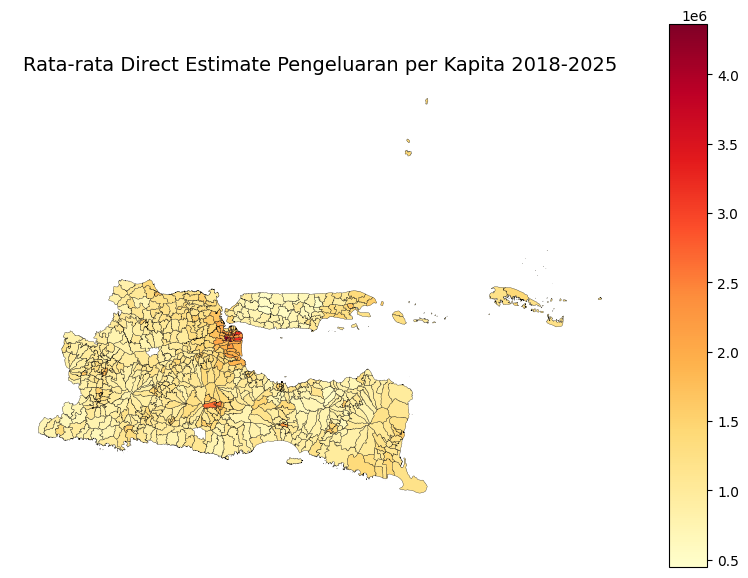

In [ ]:
plot_estimation_map(map_average, "Direct_Estimate", "Rata-rata Direct Estimate Pengeluaran per Kapita 2018-2025")

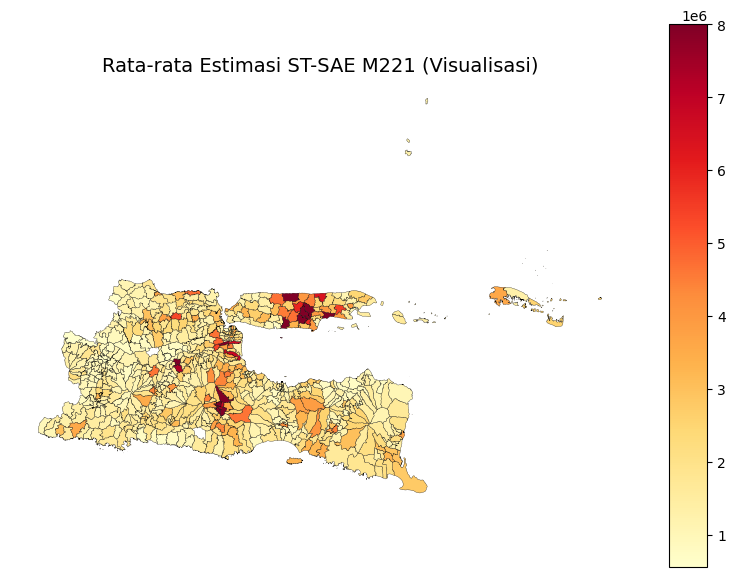

In [ ]:
plot_estimation_map(map_visual, "STSAE_M221_plot", "Rata-rata Estimasi ST-SAE M221 (Visualisasi)")

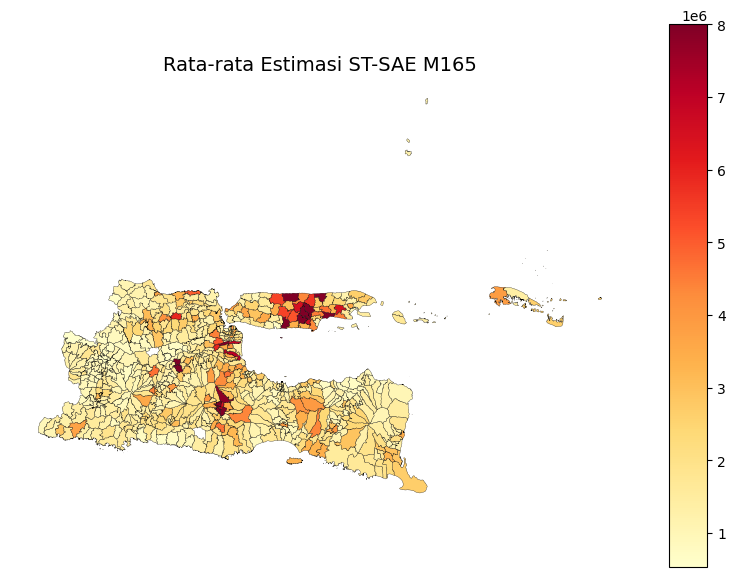

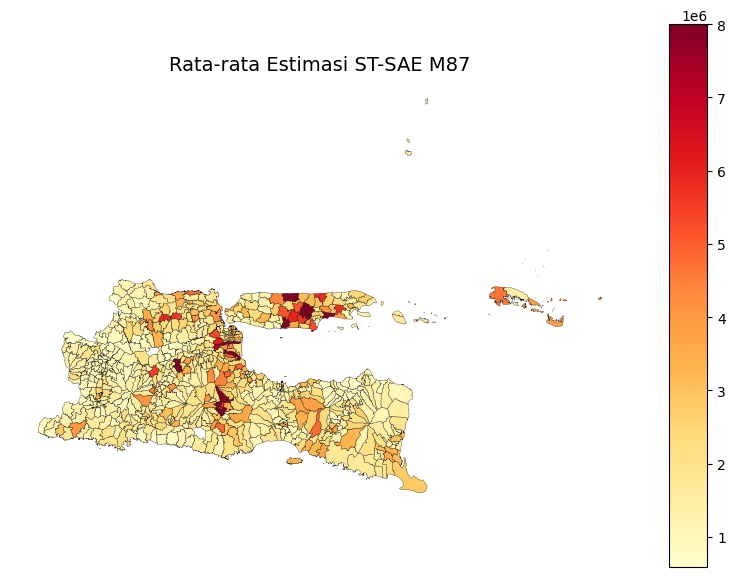

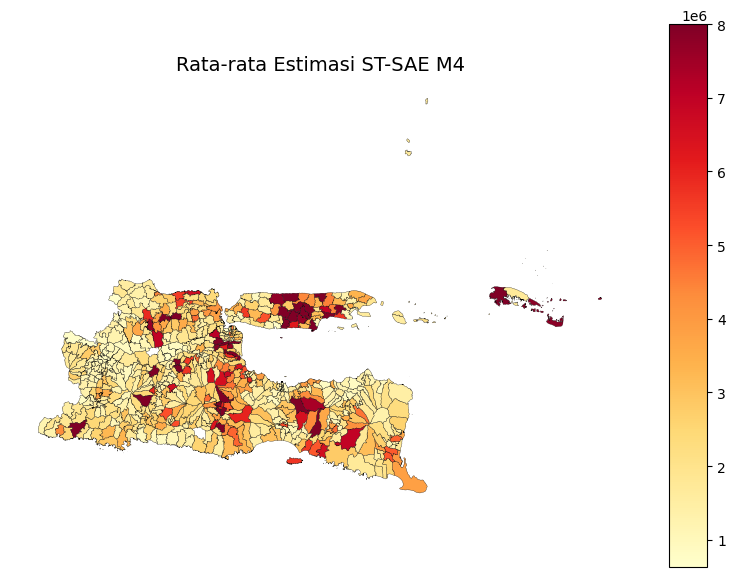

In [ ]:
plot_estimation_map(map_visual, "STSAE_M165_plot", "Rata-rata Estimasi ST-SAE M165")
plot_estimation_map(map_visual, "STSAE_M87_plot", "Rata-rata Estimasi ST-SAE M87")
plot_estimation_map(map_visual, "STSAE_M4_plot", "Rata-rata Estimasi ST-SAE M4")

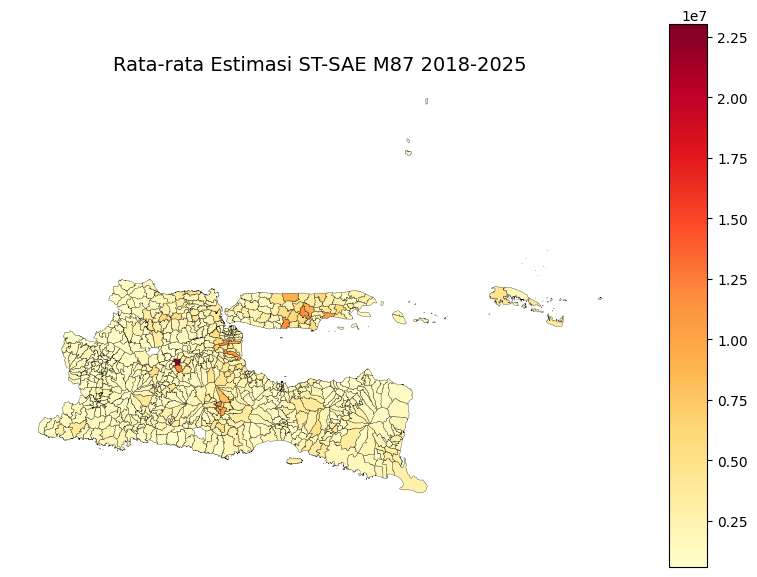

In [ ]:
plot_estimation_map(map_average, "STSAE_M87", "Rata-rata Estimasi ST-SAE M87 2018-2025")

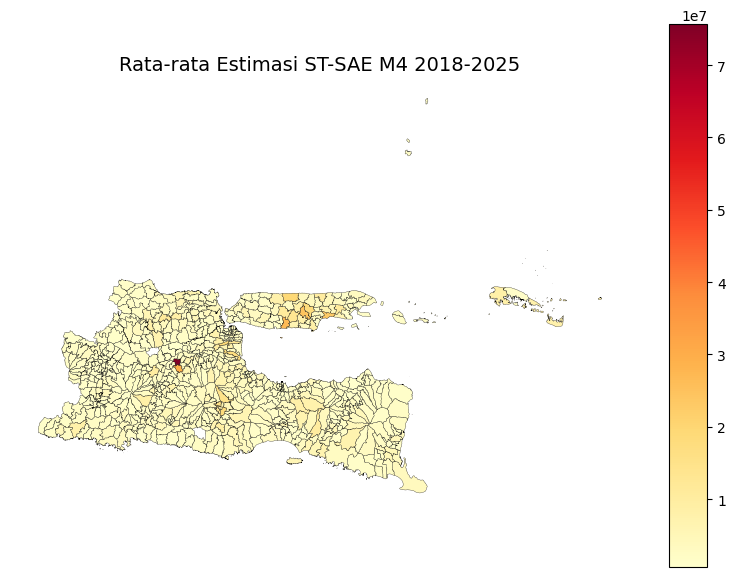

In [ ]:
plot_estimation_map(map_average, "STSAE_M4", "Rata-rata Estimasi ST-SAE M4 2018-2025")

In [ ]:
# ============================================================
# DATA RSE
# ============================================================

df_rse = pd.DataFrame()
for model_name, result in model_results.items():
    temp = pd.DataFrame({"Model": model_name, "RSE": result["RSE"]})
    df_rse = pd.concat([df_rse, temp], ignore_index=True)

display(df_rse.head())

,Model,RSE
0,M221,8.422085
1,M221,7.728443
2,M221,5.458972
3,M221,6.684819
4,M221,3.403463


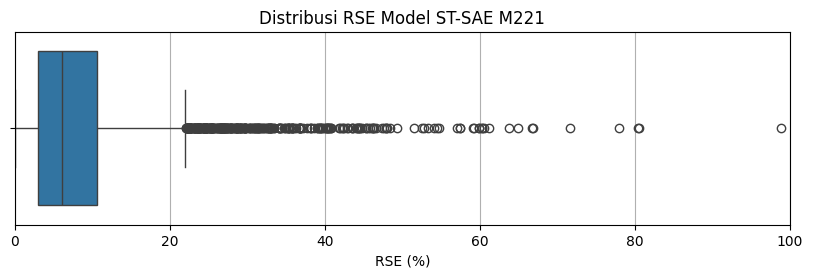

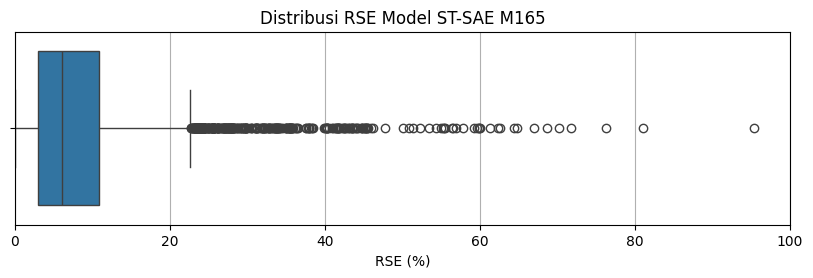

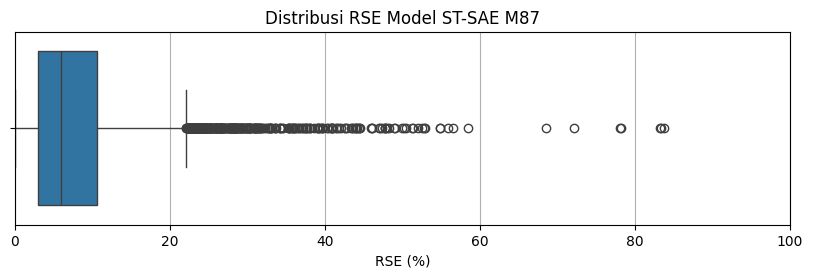

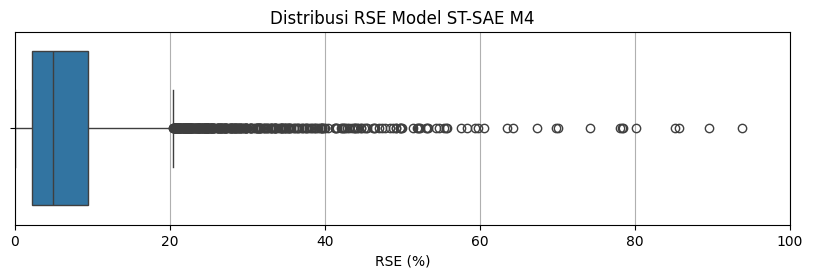

In [ ]:
# ============================================================
# BOXPLOT RSE TERPISAH SETIAP MODEL
# ============================================================

models_rse = ["M221", "M165", "M87", "M4"]
for model in models_rse:
    rse_values = model_results[model]["RSE"]
    df_plot_rse = pd.DataFrame({"RSE": rse_values})
    df_plot_rse = df_plot_rse[df_plot_rse["RSE"] <= 100]

    plt.figure(figsize=(10, 2.5))
    sns.boxplot(data=df_plot_rse, x="RSE", orient="h")
    plt.xlim(0, 100)
    plt.xlabel("RSE (%)")
    plt.title(f"Distribusi RSE Model ST-SAE {model}")
    plt.grid(axis="x")
    plt.show()

In [ ]:
# ============================================================
# BOXPLOT ESTIMASI DENGAN BATAS 8 JUTA
# ============================================================

df_box_visual = pd.DataFrame()
box_columns = ["Direct_Estimate", "STSAE_M221", "STSAE_M165", "STSAE_M87", "STSAE_M4"]
for col in box_columns:
    temp = pd.DataFrame({"Model": col, "Estimasi": df_estimation[col].clip(upper=8_000_000)})
    df_box_visual = pd.concat([df_box_visual, temp], ignore_index=True)

display(df_box_visual.head())

,Model,Estimasi
0,Direct_Estimate,661473.3105
1,Direct_Estimate,727571.1022
2,Direct_Estimate,670954.6408
3,Direct_Estimate,749145.0514
4,Direct_Estimate,648363.9275


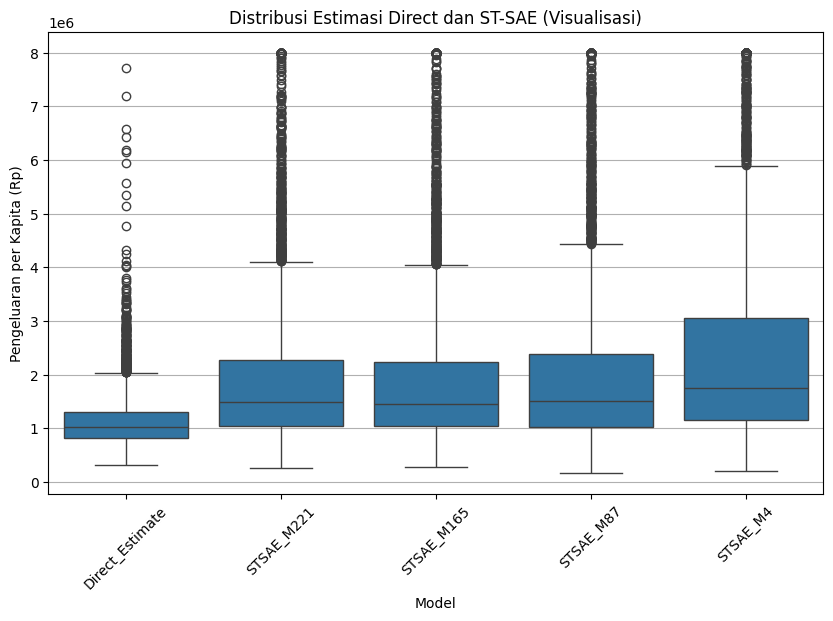

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_box_visual, x="Model", y="Estimasi")
plt.xticks(rotation=45)
plt.ylabel("Pengeluaran per Kapita (Rp)")
plt.title("Distribusi Estimasi Direct dan ST-SAE (Visualisasi)")
plt.grid(axis="y")
plt.show()

In [ ]:
# ============================================================
# BOXPLOT DIRECT ESTIMATE VS ST-SAE M87
# ============================================================

df_box_M84 = pd.DataFrame({
    "Direct Estimate": df_estimation["Direct_Estimate"],
    "ST-SAE M87": df_estimation["STSAE_M87"]
})

df_box_M84 = df_box_M84.melt(var_name="Model", value_name="Estimasi")
display(df_box_M84.head())

,Model,Estimasi
0,Direct Estimate,661473.3105
1,Direct Estimate,727571.1022
2,Direct Estimate,670954.6408
3,Direct Estimate,749145.0514
4,Direct Estimate,648363.9275


In [ ]:
for col in box_columns:
    jumlah = (df_estimation[col] > 10_000_000).sum()
    print(f"{col}: {jumlah} nilai di atas 10 juta")

Direct_Estimate : 0 nilai di atas 10 juta
STSAE_M221 : 55 nilai di atas 10 juta
STSAE_M165 : 64 nilai di atas 10 juta
STSAE_M87 : 75 nilai di atas 10 juta
STSAE_M4 : 184 nilai di atas 10 juta


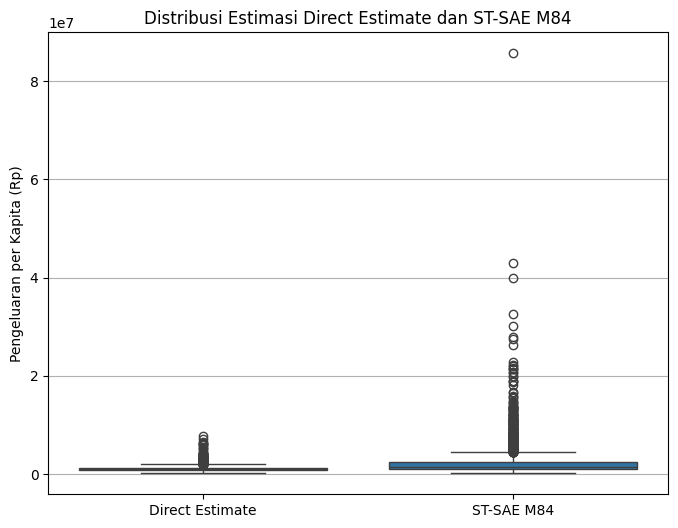

In [ ]:
plt.figure(figsize=(8, 6))
df_box_M84["Estimasi"] = df_box_M84["Estimasi"].clip(upper=10_000_000)
sns.boxplot(data=df_box_M84, x="Model", y="Estimasi")
plt.ylabel("Pengeluaran per Kapita (Rp)")
plt.xlabel("")
plt.title("Distribusi Estimasi Direct Estimate dan ST-SAE M87")
plt.grid(axis="y")
plt.show()

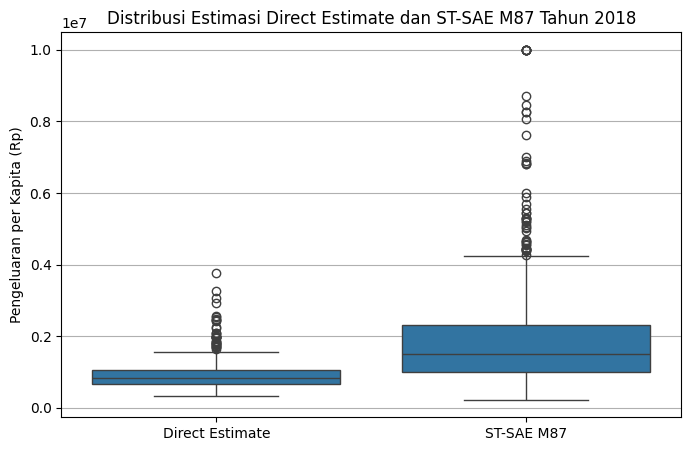

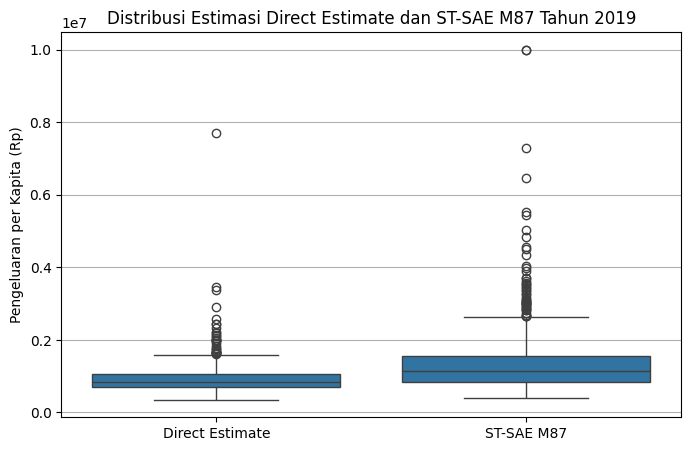

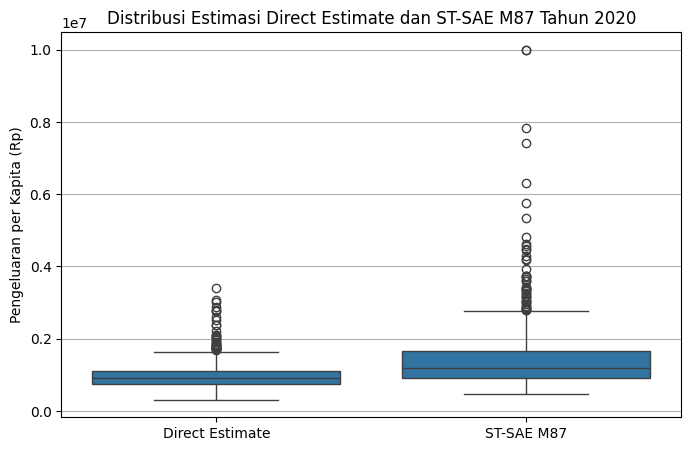

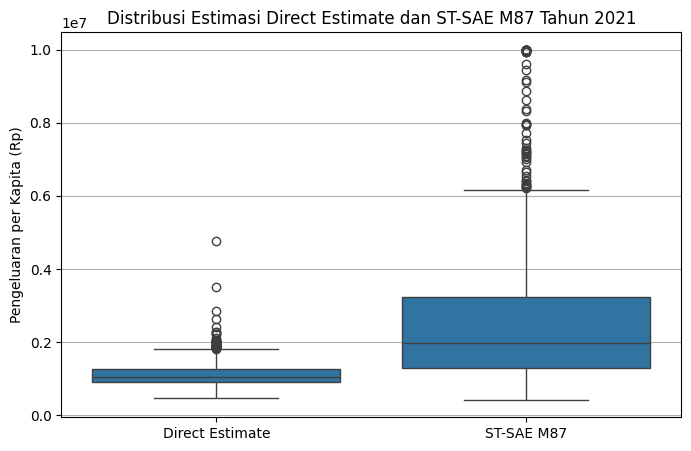

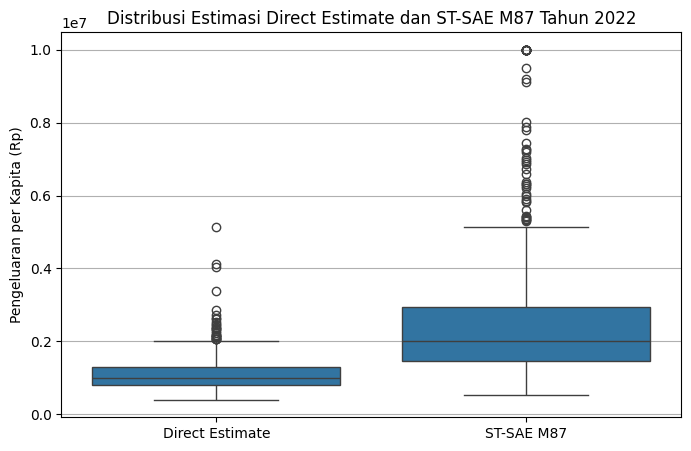

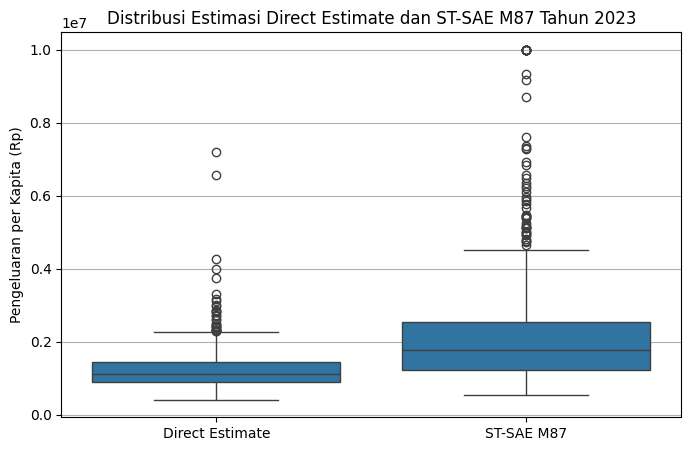

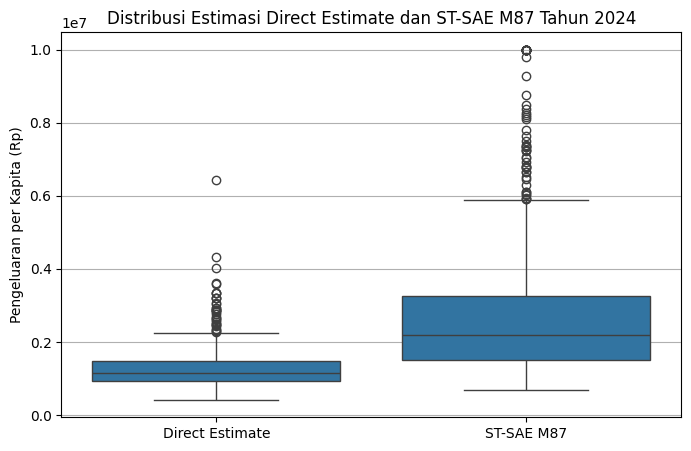

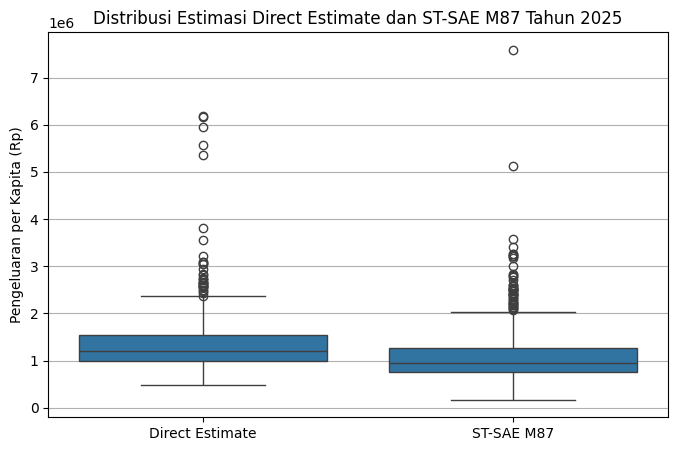

In [ ]:
# ============================================================
# BOXPLOT DIRECT ESTIMATE VS ST-SAE M87 PER TAHUN
# ============================================================

tahun_list = sorted(df_estimation["tahun"].unique())
for tahun in tahun_list:
    df_year = df_estimation[df_estimation["tahun"] == tahun].copy()
    df_box_M87_year = pd.DataFrame({
        "Direct Estimate": df_year["Direct_Estimate"],
        "ST-SAE M87": df_year["STSAE_M87"]
    })
    df_box_M87_year = df_box_M87_year.melt(var_name="Model", value_name="Estimasi")
    df_box_M87_year["Estimasi"] = df_box_M87_year["Estimasi"].clip(upper=10_000_000)

    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df_box_M87_year, x="Model", y="Estimasi")
    plt.xticks(rotation=0)
    plt.ylabel("Pengeluaran per Kapita (Rp)")
    plt.xlabel("")
    plt.title(f"Distribusi Estimasi Direct Estimate dan ST-SAE M87 Tahun {tahun}")
    plt.grid(axis="y")
    plt.show()

In [ ]:
model_results["M87"]

{'fit': <statsmodels.regression.linear_model.RegressionResultsWrapper at 0x7e330c4657f0>,
 'eblup': 0       7.419815e+05
 1       7.425166e+05
 2       9.859069e+05
 3       1.196836e+06
 4       1.194663e+06
             ...     
 5283    2.534550e+06
 5284    2.571024e+06
 5285    2.147737e+06
 5286    2.583660e+06
 5287    1.735269e+06
 Length: 5288, dtype: float64,
 'MSE': array([4.22627158e+09, 4.46802121e+09, 2.74461733e+09, ...,
        1.05442562e+10, 5.67731474e+09, 2.60848287e+10]),
 'RMSE': array([ 65009.78065906,  66843.25850996,  52389.09554903, ...,
        102685.22877808,  75347.95780242, 161507.98331393]),
 'RSE': 0       8.761644
 1       9.002258
 2       5.313797
 3       8.169778
 4       3.417748
           ...   
 5283    3.359135
 5284    4.272646
 5285    4.781090
 5286    2.916326
 5287    9.307374
 Length: 5288, dtype: float64,
 'data':       Unnamed: 0     X  kode_kecamatan_bps  tahun  jumlah_rt  \
 0              1     1             3501010   2018         5

In [ ]:
# ============================================================
# TABEL MSE DAN RRMSE ST-SAE M87 PER TAHUN
# ============================================================

hasil_M87 = df_run[["kode_kecamatan_bps", "tahun"]].copy()
hasil_M87["MSE_M87"] = model_results["M87"]["MSE"]
hasil_M87["RMSE_M87"] = model_results["M87"]["RMSE"]
hasil_M87["RRMSE_M87"] = model_results["M87"]["RSE"]

display(hasil_M87.head())

,kode_kecamatan_bps,tahun,MSE_M87,RMSE_M87,RRMSE_M87
0,3501010,2018,4.134102e+09,64296.986516,8.665578
1,3501010,2019,5.018611e+09,70842.155540,9.540818
2,3501010,2020,2.220446e+09,47121.606326,4.779519
3,3501010,2021,8.228744e+09,90712.423140,7.579354
4,3501010,2022,1.789366e+09,42300.897166,3.540822


In [ ]:
# ============================================================
# RINGKASAN TAHUNAN M87
# ============================================================

summary_M87_tahun = hasil_M87.groupby("tahun").agg(
    Mean_MSE=("MSE_M87", "mean"),
    Median_MSE=("MSE_M87", "median"),
    Mean_RRMSE=("RRMSE_M87", "mean"),
    Median_RRMSE=("RRMSE_M87", "median"),
    Proporsi_RRMSE_kurang25=("RRMSE_M87", lambda x: (x < 25).mean() * 100)
).reset_index()

display(summary_M87_tahun)

,tahun,Mean_MSE,Median_MSE,Mean_RRMSE,Median_RRMSE,Proporsi_RRMSE_kurang25
0,2018,2.310452e+10,6.331399e+09,6.845731,4.872848,97.125567
1,2019,5.227913e+10,6.389378e+09,8.803280,6.659076,96.217852
2,2020,2.372397e+10,7.739987e+09,8.636481,6.824873,96.671710
3,2021,2.010173e+10,6.639783e+09,5.406668,3.587084,98.335855
4,2022,3.710932e+10,1.014197e+10,6.705117,4.958794,98.033283
5,2023,7.981972e+10,1.436491e+10,9.096767,6.641112,95.461422
6,2024,5.235000e+10,1.440392e+10,7.114741,5.418535,96.822995
7,2025,6.088401e+10,1.364860e+10,15.040059,11.605499,84.266263


In [ ]:
# ============================================================
# MEMBUAT DATA FRAME HASIL ESTIMASI DIRECT + ST-SAE
# ============================================================

df_estimation = df_run[["kode_kecamatan_bps", "kode_kecamatan_kemendagri", "tahun", "pengeluaran_mean", "VAR...8"]].copy()
df_estimation.rename(columns={"pengeluaran_mean": "Direct_Estimate", "VAR...8": "MSE_Direct"}, inplace=True)

for model_name, result in model_results.items():
    df_estimation[f"STSAE_{model_name}"] = result["eblup"]

display(df_estimation.head())

,kode_kecamatan_bps,kode_kecamatan_kemendagri,tahun,Direct_Estimate,MSE_Direct,STSAE_M221,STSAE_M165,STSAE_M87,STSAE_M4
0,3501010,35.01.01,2018,661473.3105,4.034213e+09,7.834733e+05,7.713756e+05,7.419815e+05,1.097998e+06
1,3501010,35.01.01,2019,727571.1022,4.407177e+09,8.246518e+05,8.359024e+05,7.425166e+05,9.960477e+05
2,3501010,35.01.01,2020,670954.6408,2.615010e+09,9.712536e+05,9.714492e+05,9.859069e+05,1.254513e+06
3,3501010,35.01.01,2021,749145.0514,6.772046e+09,1.141799e+06,1.124267e+06,1.196836e+06,1.585198e+06
4,3501010,35.01.01,2022,648363.9275,1.702272e+09,1.258967e+06,1.222934e+06,1.194663e+06,1.578845e+06


In [ ]:
# ============================================================
# HITUNG RMSE DAN RRMSE DIRECT & M87
# ============================================================

df_estimation["RMSE_Direct"] = np.sqrt(df_estimation["MSE_Direct"])
df_estimation["RRMSE_Direct"] = (df_estimation["RMSE_Direct"] / df_estimation["Direct_Estimate"]) * 100

df_estimation["MSE_M87"] = model_results["M87"]["MSE"]
df_estimation["RMSE_M87"] = np.sqrt(df_estimation["MSE_M87"])
df_estimation["RRMSE_M87"] = (df_estimation["RMSE_M87"] / df_estimation["STSAE_M87"]) * 100

display(df_estimation.head(8))

,kode_kecamatan_bps,kode_kecamatan_kemendagri,tahun,Direct_Estimate,MSE_Direct,STSAE_M221,STSAE_M165,STSAE_M87,STSAE_M4,RMSE_Direct,RRMSE_Direct,MSE_M87,RMSE_M87,RRMSE_M87
0,3501010,35.01.01,2018,661473.3105,4.034213e+09,7.834733e+05,7.713756e+05,7.419815e+05,1.097998e+06,63515.453096,9.602119,4.134102e+09,64296.986516,8.665578
1,3501010,35.01.01,2019,727571.1022,4.407177e+09,8.246518e+05,8.359024e+05,7.425166e+05,9.960477e+05,66386.570600,9.124410,5.018611e+09,70842.155540,9.540818
2,3501010,35.01.01,2020,670954.6408,2.615010e+09,9.712536e+05,9.714492e+05,9.859069e+05,1.254513e+06,51137.172243,7.621554,2.220446e+09,47121.606326,4.779519
3,3501010,35.01.01,2021,749145.0514,6.772046e+09,1.141799e+06,1.124267e+06,1.196836e+06,1.585198e+06,82292.439531,10.984847,8.228744e+09,90712.423140,7.579354
4,3501010,35.01.01,2022,648363.9275,1.702272e+09,1.258967e+06,1.222934e+06,1.194663e+06,1.578845e+06,41258.594390,6.363493,1.789366e+09,42300.897166,3.540822
5,3501010,35.01.01,2023,607533.3423,2.675708e+09,1.101291e+06,1.068204e+06,9.182582e+05,1.237226e+06,51727.245529,8.514306,3.294817e+09,57400.496913,6.251019
6,3501010,35.01.01,2024,609835.5636,4.149778e+09,1.003788e+06,9.879552e+05,9.380884e+05,1.214084e+06,64418.768756,10.563301,3.914984e+09,62569.835931,6.669930
7,3501010,35.01.01,2025,978634.4793,9.259514e+09,7.667604e+05,7.321249e+05,6.939829e+05,8.475095e+05,96226.366013,9.832718,9.534705e+09,97645.813127,14.070349


In [ ]:
# ============================================================
# RINGKASAN RRMSE DIRECT VS M87 PER TAHUN
# ============================================================

summary_RRMSE_M87 = df_estimation.groupby("tahun").agg(
    Mean_RRMSE_Direct=("RRMSE_Direct", "mean"),
    Median_RRMSE_Direct=("RRMSE_Direct", "median"),
    Mean_RRMSE_M87=("RRMSE_M87", "mean"),
    Median_RRMSE_M87=("RRMSE_M87", "median")
).reset_index()

display(summary_RRMSE_M87)

,tahun,Mean_RRMSE_Direct,Median_RRMSE_Direct,Mean_RRMSE_M87,Median_RRMSE_M87
0,2018,10.527358,9.580867,6.845731,4.872848
1,2019,10.330659,9.440283,8.803280,6.659076
2,2020,10.680746,9.798144,8.636481,6.824873
3,2021,8.598814,7.602980,5.406668,3.587084
4,2022,11.611951,10.512829,6.705117,4.958794
5,2023,12.123411,10.686369,9.096767,6.641112
6,2024,11.473181,10.226678,7.114741,5.418535
7,2025,10.645408,9.872265,15.040059,11.605499


In [ ]:
# ============================================================
# BAGIAN 6: PENYIMPANAN HASIL ESTIMASI ST-SAE M87
# ============================================================

import os
output_path = "/content/drive/MyDrive/data_skripsi/hasil_stsae/"
os.makedirs(output_path, exist_ok=True)

# 1. Simpan hasil estimasi tingkat kecamatan
hasil_estimasi_M87 = df_estimation[[
    "kode_kecamatan_bps", "kode_kecamatan_kemendagri", "tahun",
    "Direct_Estimate", "MSE_Direct", "RMSE_Direct", "RRMSE_Direct",
    "STSAE_M87", "MSE_M87", "RMSE_M87", "RRMSE_M87"
]].copy()
hasil_estimasi_M87.to_csv(output_path + "hasil_estimasi_STSAE_M87_level_kecamatan.csv", index=False)
print("Tersimpan: hasil_estimasi_STSAE_M87_level_kecamatan.csv")

# 2. Simpan hasil EBLUP M87
hasil_EBLUP_M87 = df_run[["kode_kecamatan_bps", "kode_kecamatan_kemendagri", "tahun"]].copy()
hasil_EBLUP_M87["EBLUP_M87"] = model_results["M87"]["eblup"]
hasil_EBLUP_M87.to_csv(output_path + "EBLUP_STSAE_M87.csv", index=False)
print("Tersimpan: EBLUP_STSAE_M87.csv")

# 3. Simpan evaluasi MSE dan RRMSE M87 per tahun
summary_M87_tahun.to_csv(output_path + "evaluasi_MSE_RRMSE_M87_tahunan.csv", index=False)
print("Tersimpan: evaluasi_MSE_RRMSE_M87_tahunan.csv")

# 4. Simpan perbandingan Direct Estimate vs ST-SAE M87
summary_RRMSE_M87.to_csv(output_path + "perbandingan_RRMSE_Direct_vs_M87.csv", index=False)
print("Tersimpan: perbandingan_RRMSE_Direct_vs_M87.csv")

# 5. Simpan evaluasi semua model
df_model_eval.to_csv(output_path + "evaluasi_semua_model_STSAE.csv", index=False)
print("Tersimpan: evaluasi_semua_model_STSAE.csv")

# 6. Simpan tabel spesifikasi model
df_model_table.to_csv(output_path + "spesifikasi_model_STSAE.csv", index=False)
print("Semua hasil berhasil disimpan")

Tersimpan: hasil_estimasi_STSAE_M87_level_kecamatan.csv
Tersimpan: EBLUP_STSAE_M87.csv
Tersimpan: evaluasi_MSE_RRMSE_M87_tahunan.csv
Tersimpan: perbandingan_RRMSE_Direct_vs_M87.csv
Tersimpan: evaluasi_semua_model_STSAE.csv
Semua hasil berhasil disimpan


In [ ]:
gdf_result.to_file(output_path + "hasil_peta_STSAE_M87.geojson", driver="GeoJSON")

In [ ]:
import geopandas as gpd
from google.colab import drive

drive.mount("/content/drive")

# membaca geojson

gdf = gpd.read_file(
    "/content/drive/MyDrive/data_skripsi/hasil_stsae/hasil_peta_STSAE_M87.geojson"
)


print(
    gdf.shape
)

Mounted at /content/drive
(5288, 18)


In [ ]:
import os
size_mb = os.path.getsize("/content/drive/MyDrive/data_skripsi/hasil_stsae/hasil_peta_STSAE_M87.geojson") / (1024 * 1024)
print(size_mb, "MB")

gdf["geometry"] = gdf.geometry.simplify(tolerance=0.001, preserve_topology=True)
gdf.to_file("/content/drive/MyDrive/data_skripsi/hasil_stsae/hasil_peta_STSAE_M87_simple.geojson", driver="GeoJSON")

430.8489761352539 MB


In [ ]:
size_mb = os.path.getsize("/content/drive/MyDrive/data_skripsi/hasil_stsae/hasil_peta_STSAE_M87_simple.geojson") / (1024 * 1024)
print(size_mb, "MB")

17.687079429626465 MB


Transformasi logaritma natural